# Curve curation walkthrough: hail × real estate

**Start here.** This notebook shows how the `hail_real_estate` curves are built: hail damages a building mainly
through its roof cover, so each curve is the chance the roof cover needs replacing at a given hailstone size,
multiplied into the roof's share of the building's replacement cost. Walls and windows are a separate,
judgment-only (Tier-4) unit.

The companion [`01_runtime_curve_walkthrough.ipynb`](01_runtime_curve_walkthrough.ipynb) calls the curves the way
Hazard would.

Status: **noncanonical proposal** (model v0.1 / docs r1). The cell documents in `docs/cells/hail_real_estate/` are
the source of truth; this notebook only reads them.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "hail_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "hail_real_estate__model_v0_1__docs_r1__curve_artifact.json"
REG = "hail_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/hail/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])

import derive_hail_real_estate_curves as derive

artifact: docs/cells/hail_real_estate/proposed/hail_real_estate__model_v0_1__docs_r1__curve_artifact.json
hail_real_estate | model v0.1 | HAIL_REAL_ESTATE_ROOF_THRESHOLD_SCREENING_V0_1 | promotion: proposed | canonical: False


## 1. What the cell is

One pathway (`hail_impact`) on Hazard's hail-size field `mesh_diameter_mm`. Unlike the wind and flood cells, the
building is split into parts, each with its own damage ratio **on its own value**:

| Unit | Treatment |
|---|---|
| Roof cover | primary curve |
| Walls and windows | Tier-4 judgment curve; used only with an explicit acknowledgement |
| Outdoor equipment, contents | withheld, not zero |

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)
shares = pd.DataFrame({u["id"]: u["share_of_structure_rcn"] for u in ART["failure_units"] if "share_of_structure_rcn" in u})
shares.index = [NAMES[b] for b in shares.index]
display(Markdown("**Each unit's share of the building's replacement cost new:**"))
display(shares.style.format("{:.2%}"))

,field,value
0,cell,hail_real_estate
1,damage code,HAIL_REAL_ESTATE_ROOF_THRESHOLD_SCREENING_V0_1
2,model / docs,model v0.1 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_material_threshold_component_curves


,id,treatment,denominator
0,HRE_ROOF_COVER,primary_nonzero,replacement cost of the same building's roof cover (house shingles; warehouse steel panels; office TPO membrane and insulation)
1,HRE_WALLS_AND_WINDOWS,secondary_conditional,replacement cost of the same building's hail-vulnerable wall cladding and windows (house vinyl siding and windows; warehouse and office windows)
2,HRE_EXPOSED_EQUIPMENT,withheld,replacement cost of the outdoor AC condenser / rooftop units (not allocated)
3,HRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,hail_impact,mesh_diameter_mm,mm,"[0.0, 203.2]",reference_building_id,-,6


**Each unit's share of the building's replacement cost new:**

,HRE_ROOF_COVER,HRE_WALLS_AND_WINDOWS
House,3.75%,6.07%
Warehouse,12.00%,0.57%
Office,2.70%,5.34%


## 2. Evidence register

In [3]:
src = table(f"SOURCE_REGISTER_{REG}.csv")
src["citation"] = src["citation"].str.slice(0, 110)
display(src[["source_id", "citation", "source_role", "evidence_tier", "decision"]])

,source_id,citation,source_role,evidence_tier,decision
0,HRE-S001,"Marshall, T. P., R. F. Herzog, S. J. Morrison and S. R. Smith (Haag Engineering Co.). Hail damage threshold si",curve_data_carrier;method_definition,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
1,HRE-S002,"Morrison, S. J. (Haag Engineering Co.). Holy hail! (part two: low-slope roof systems). Professional Roofing, N",curve_data_carrier;method_definition,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
2,HRE-S003,"Kestner, J. (Haag Engineering Co.) and K. J. Kennedy. Testing your mettle: what you need to know about court r",method_definition;independent_verification,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
3,HRE-S004,"Olson, E. (Simpson Gumpertz & Heger). Understanding hail damage risks for roofing and wall systems. SGH topic",independent_verification,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
4,HRE-S005,"Bhawalkar, S., L. Yang and T. Taylor. Ice ball impact resistance of heat-aged TPO roofing membranes. IIBEC Int",independent_verification,T3_engineering_proxy_or_adjacent_empirical,adopt_with_limits
5,HRE-S006,FEMA. Hazus 7.0 Hurricane Model Technical Manual (June 2025).,value_basis,T2_public_lab_standard_or_physics,adopt_with_limits
6,HRE-S007,"Hazard reference profiles r1: aamani-ai/Hazard_Modeling commit 8b0d61c88fbcf85daa1c098516cee22398cdb524, docs/",selector_archetype;value_basis,T4_placeholder_or_expert_judgment,adopt
7,HRE-S008,Hazard hail pipeline on aamani-ai/Hazard_Modeling main (commit 20de3770b039d709b6867578dcb6d0672c2c7234): peri,axis_bridge,T4_placeholder_or_expert_judgment,adopt
8,HRE-S009,"Schmid, T., R. Portmann, L. Villiger, K. Schröer and D. N. Bresch. An open-source radar-based hail damage mode",independent_verification,T3_engineering_proxy_or_adjacent_empirical,context_only
9,HRE-S010,"Meisenzahl, B., I. Giammanco and F. Hedayati (IBHS). Sub-severe hail: the missing piece in assessing asphalt s",limitation,T3_engineering_proxy_or_adjacent_empirical,context_only


## 3. The component table: hail size at which each part fails

For each part, the evidence gives an **onset** size (real damage starts) and a **full** size (the part is
replaced almost everywhere). The roof thresholds come from Haag's published hail-damage studies by roofing
material; the wall and window values are judgment (Tier 4). Each part also has an exposure share (a roof is hit
everywhere; walls and windows only on the side facing the storm) and a value share of the building.

In [4]:
parts = table(f"COMPONENT_FRAGILITY_TABLE_{REG}.csv")
display(parts[["reference_building_id", "failure_unit_id", "part_id", "onset_in", "full_in", "exposure_fraction",
               "part_value_fraction_of_structure_rcn", "threshold_tier", "value_tier"]])

,reference_building_id,failure_unit_id,part_id,onset_in,full_in,exposure_fraction,part_value_fraction_of_structure_rcn,threshold_tier,value_tier
0,RE_RES_SFD_1S_SLAB,HRE_ROOF_COVER,ROOF_ASPHALT_SHINGLE_LAMINATED,1.25,2.0,1.00,0.037500,T3_engineering_proxy_or_adjacent_empirical,T3_engineering_proxy_or_adjacent_empirical
1,RE_RES_SFD_1S_SLAB,HRE_WALLS_AND_WINDOWS,WALL_VINYL_SIDING,1.25,2.0,0.50,0.027689,T4_placeholder_or_expert_judgment,T4_placeholder_or_expert_judgment
2,RE_RES_SFD_1S_SLAB,HRE_WALLS_AND_WINDOWS,WINDOWS_RESIDENTIAL,1.50,2.5,0.25,0.033000,T4_placeholder_or_expert_judgment,T4_placeholder_or_expert_judgment
3,RE_IND_WAREHOUSE,HRE_ROOF_COVER,ROOF_STANDING_SEAM_STEEL,2.50,3.5,1.00,0.120000,T3_engineering_proxy_or_adjacent_empirical,T4_placeholder_or_expert_judgment
4,RE_IND_WAREHOUSE,HRE_WALLS_AND_WINDOWS,WINDOWS_COMMERCIAL,1.50,2.5,0.25,0.005673,T4_placeholder_or_expert_judgment,T4_placeholder_or_expert_judgment
5,RE_COM_OFFICE_3S_SLAB,HRE_ROOF_COVER,ROOF_TPO_MEMBRANE_AND_INSULATION,1.00,2.0,1.00,0.027000,T3_engineering_proxy_or_adjacent_empirical,T3_engineering_proxy_or_adjacent_empirical
6,RE_COM_OFFICE_3S_SLAB,HRE_WALLS_AND_WINDOWS,WINDOWS_COMMERCIAL,1.50,2.5,0.25,0.053387,T4_placeholder_or_expert_judgment,T4_placeholder_or_expert_judgment


## 4. From thresholds to a curve

Each part's chance of replacement is lognormal in hailstone size, with the onset at 5% and the full size at 95%:

```text
P(D) = Φ( ln(D / √(onset × full)) / β ),   β = ln(full / onset) / (2 × 1.645)
DR_unit(D) = Σ_parts (part value / unit value) × exposure × P(D)
```

The derive script tabulates this every 1 mm from 0 to 203.2 mm. The notebook recomputes it from the component
table and compares with the artifact.

,curve_id,knots,max |recomputed - artifact|
0,HRE_RES_ROOF_ASPHALT_SHINGLE_LAMINATED,205,0.0
1,HRE_IND_ROOF_STANDING_SEAM_STEEL,205,0.0
2,HRE_OFF_ROOF_TPO_MEMBRANE_AND_INSULATION,205,0.0
3,HRE_RES_WALLS_WINDOWS_T4,205,0.0
4,HRE_IND_WINDOWS_T4,205,0.0
5,HRE_OFF_WINDOWS_T4,205,0.0


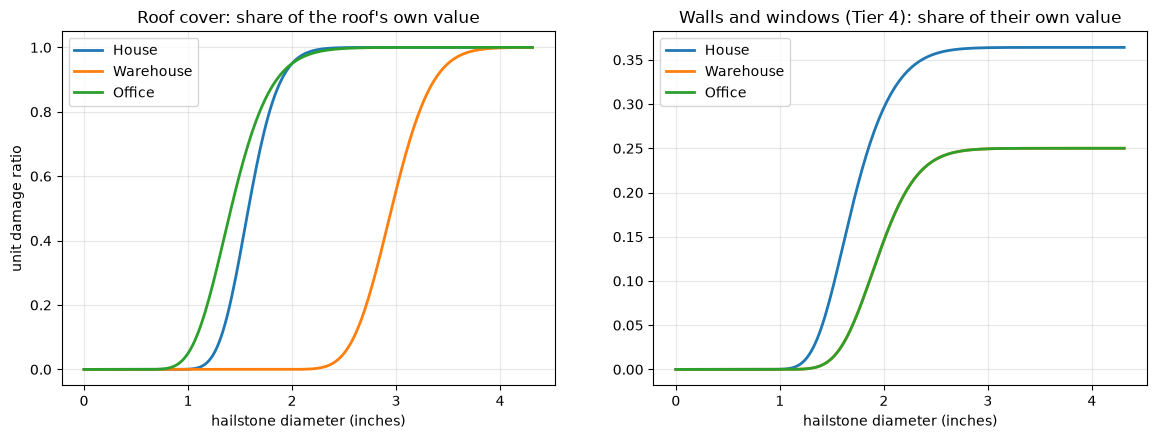

In [5]:
tab = derive.parts_table()
check = []
for r in ART["pathways"][0]["curve_records"]:
    key = (r["selector_match"]["reference_building_id"], r["failure_unit_id"])
    diff = max(abs(round(derive.unit_dr(tab[key], x), 6) - y) for x, y in r["parameters"]["points"])
    check.append({"curve_id": r["curve_id"], "knots": len(r["parameters"]["points"]), "max |recomputed - artifact|": diff})
display(pd.DataFrame(check))

d = np.arange(0, 110, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for b in derive.BUILDINGS:
    axes[0].plot(d / 25.4, [derive.unit_dr(tab[(b, "HRE_ROOF_COVER")], x) for x in d], lw=2, label=NAMES[b])
    axes[1].plot(d / 25.4, [derive.unit_dr(tab[(b, "HRE_WALLS_AND_WINDOWS")], x) for x in d], lw=2, label=NAMES[b])
axes[0].set_title("Roof cover: share of the roof's own value")
axes[1].set_title("Walls and windows (Tier 4): share of their own value")
for ax in axes:
    ax.set_xlabel("hailstone diameter (inches)")
    ax.legend()
axes[0].set_ylabel("unit damage ratio")
save(fig, "00_unit_curves.png")
plt.show()

## 5. Building-level damage

To compare with the other real-estate cells, the unit ratios are weighted by each unit's share of the building:
`building % = Σ unit DR × unit share`. The roof shares are FEMA Hazus cost ratios for the house and office and a
judgment value (12%) for the warehouse.

In [6]:
share = {u["id"]: u["share_of_structure_rcn"] for u in ART["failure_units"] if "share_of_structure_rcn" in u}
rows = []
for b in derive.BUILDINGS:
    for size in (1.0, 1.25, 1.5, 2.0, 2.5, 3.0):
        x = size * 25.4
        roof = derive.unit_dr(tab[(b, "HRE_ROOF_COVER")], x) * share["HRE_ROOF_COVER"][b]
        walls = derive.unit_dr(tab[(b, "HRE_WALLS_AND_WINDOWS")], x) * share["HRE_WALLS_AND_WINDOWS"][b]
        rows.append({"building": NAMES[b], "hail (in)": size, "roof": roof, "walls and windows (T4)": walls, "total": roof + walls})
bl = pd.DataFrame(rows)
display(bl.pivot(index="building", columns="hail (in)", values="roof").rename(columns=lambda c: f"{c:g} in").style.format("{:.2%}").set_caption("Roof cover, % of building value"))
display(bl.pivot(index="building", columns="hail (in)", values="total").rename(columns=lambda c: f"{c:g} in").style.format("{:.2%}").set_caption("Roof + walls and windows, % of building value"))

hail (in),1 in,1.25 in,1.5 in,2 in,2.5 in,3 in
building,,,,,,
House,0.00%,0.19%,1.34%,3.56%,3.75%,3.75%
Office,0.13%,0.75%,1.65%,2.57%,2.69%,2.70%
Warehouse,0.00%,0.00%,0.00%,0.00%,0.60%,6.66%


hail (in),1 in,1.25 in,1.5 in,2 in,2.5 in,3 in
building,,,,,,
House,0.00%,0.26%,1.87%,5.36%,5.91%,5.96%
Office,0.13%,0.76%,1.71%,3.34%,3.96%,4.03%
Warehouse,0.00%,0.00%,0.01%,0.08%,0.73%,6.80%


## 6. NRI check and Hazard's hail-size field

Hazard sends MESH75, a radar-based hail size that is at least about 39 mm (1.5 in) in every severe-hail pixel,
which is already past the shingle and membrane onsets. The NRI check (a check, not a calibration) shows how much
that one Hazard step drives the yearly loss, compared with Hazard's earlier size conversion.

In [7]:
nri = table(f"NRI_CHECK_{REG}.csv")
display(nri[["reference_building_id", "variant", "ours_median_pct_per_year", "nri_median_pct_per_year",
             "ours_over_nri_median", "spearman_rank_corr"]])

,reference_building_id,variant,ours_median_pct_per_year,nri_median_pct_per_year,ours_over_nri_median,spearman_rank_corr
0,RE_RES_SFD_1S_SLAB,central: roof cover only,0.11222,0.00141,72.90,0.696
1,RE_RES_SFD_1S_SLAB,central: roof cover + walls and windows (T4),0.16173,0.00141,104.75,0.694
2,RE_RES_SFD_1S_SLAB,"central roof cover, Hazard Version-1 size transform (raw x 25.4/35.56)",0.00123,0.00141,1.19,0.565
3,RE_IND_WAREHOUSE,central: roof cover only,0.00000,0.00141,0.01,0.502
4,RE_IND_WAREHOUSE,central: roof cover + walls and windows (T4),0.00144,0.00141,0.96,0.627
5,RE_IND_WAREHOUSE,"central roof cover, Hazard Version-1 size transform (raw x 25.4/35.56)",0.00000,0.00141,0.00,0.326
6,RE_COM_OFFICE_3S_SLAB,central: roof cover only,0.09889,0.00141,63.87,0.702
7,RE_COM_OFFICE_3S_SLAB,central: roof cover + walls and windows (T4),0.11189,0.00141,72.29,0.697
8,RE_COM_OFFICE_3S_SLAB,"central roof cover, Hazard Version-1 size transform (raw x 25.4/35.56)",0.00558,0.00141,4.35,0.614
9,RE_RES_SFD_1S_SLAB,roof low: no Hazus repair factor (3.0%),0.08982,0.00141,58.35,0.696


## 7. Sensitivity

Low and high cases (spread reading, shingle type, membrane attachment, warehouse roof share and full size). Shown here at building level.

In [8]:
sens = table(f"SENSITIVITY_{REG}.csv")
display(sens[sens.metric == "building_pct_of_structure_rcn"].drop(columns="metric"))

,reference_building_id,failure_unit_id,variant,role,at_1in,at_1.25in,at_1.5in,at_1.75in,at_2in,at_2.5in,at_3in,at_4in
1,RE_RES_SFD_1S_SLAB,HRE_ROOF_COVER,reference (central),reference,0.003,0.187,1.336,2.855,3.563,3.747,3.750,3.750
3,RE_RES_SFD_1S_SLAB,HRE_WALLS_AND_WINDOWS,reference (central),reference,0.001,0.071,0.534,1.266,1.796,2.167,2.207,2.209
5,RE_IND_WAREHOUSE,HRE_ROOF_COVER,reference (central),reference,0.000,0.000,0.000,0.000,0.001,0.600,6.657,11.981
7,RE_IND_WAREHOUSE,HRE_WALLS_AND_WINDOWS,reference (central),reference,0.000,0.000,0.007,0.036,0.083,0.135,0.141,0.142
9,RE_COM_OFFICE_3S_SLAB,HRE_ROOF_COVER,reference (central),reference,0.135,0.753,1.647,2.279,2.565,2.691,2.700,2.700
11,RE_COM_OFFICE_3S_SLAB,HRE_WALLS_AND_WINDOWS,reference (central),reference,0.000,0.003,0.067,0.343,0.777,1.268,1.331,1.335
13,RE_RES_SFD_1S_SLAB,HRE_ROOF_COVER,band read as +/-1 sigma (68% range),spread_reading,0.096,0.595,1.542,2.501,3.155,3.654,3.738,3.750
15,RE_RES_SFD_1S_SLAB,HRE_ROOF_COVER,band read as +/-1.96 sigma (95% range),spread_reading,0.000,0.094,1.238,3.005,3.656,3.750,3.750,3.750
17,RE_RES_SFD_1S_SLAB,HRE_WALLS_AND_WINDOWS,band read as +/-1 sigma (68% range),spread_reading,0.039,0.255,0.700,1.209,1.619,2.043,2.169,2.208
19,RE_RES_SFD_1S_SLAB,HRE_WALLS_AND_WINDOWS,band read as +/-1.96 sigma (95% range),spread_reading,0.000,0.035,0.478,1.290,1.843,2.189,2.209,2.209


## 8. Decisions

In [9]:
log = decision_log(PROP / f"DECISION_LOG_{REG}.md")
display(log.groupby("status").size().rename("decisions").to_frame())
display(log)

,decisions
status,
JL decided,8
proposed,8


,id,status,decision
0,D-HRE-01,JL decided,"JL decided — roof-cover curves. Each building's curve is the chance its roof cover needs replacing at a given hail size (Haag material thresholds), and its ..."
1,D-HRE-02,proposed,"One cell, `hail_real_estate`, for the three Hazard reference profiles r1: house `RE_RES_SFD_1S_SLAB`, warehouse `RE_IND_WAREHOUSE`, office `RE_COM_OFFICE_3S..."
2,D-HRE-03,proposed,"One pathway with the repository's existing ID, `hail_impact` (the hail × wind proposal uses the same ID). The axis is `mesh_diameter_mm` exactly as Hazard d..."
3,D-HRE-04,JL decided,"JL decided — failure units. `HRE_ROOF_COVER` (primary); `HRE_WALLS_AND_WINDOWS`, a separate Tier-4 screening unit; `HRE_EXPOSED_EQUIPMENT` (AC condenser, ro..."
4,D-HRE-05,JL decided,"JL decided — real damage only. Only damage that impairs function is counted: punctured, fractured or ruptured cover, or open seams. Cosmetic denting of the ..."
5,D-HRE-06,JL decided,JL decided — y-axis on the part's own value. Each unit's damage ratio is a fraction of that unit's own replacement cost. The unit's share of structure repla...
6,D-HRE-07,JL decided,"JL decided (2026-10-19). Roof thresholds. House: laminated shingles, onset 1.25 in, full 2.0 in. Office: TPO, 1.0–2.0 in. Warehouse: standing-seam steel, on..."
7,D-HRE-08,proposed,"Curve form. Each part's replacement probability is lognormal in hail diameter, with onset = 5% and full = 95% (median = √(onset·full), β = ln(full/onset)/3...."
8,D-HRE-09,JL decided,JL decided (2026-10-19). Roof cost shares (of structure replacement cost new). House 3.75% = Hazus one-storey roofing 3% × repair factor 1.25. Office 2.7% =...
9,D-HRE-10,JL decided,"JL decided (2026-10-19). Walls and windows (Tier-4). House vinyl siding: 1.25–2.0 in, half on hail-facing elevations, $7/ft² × 1,602 ft². Windows: 1.5–2.5 i..."


## 9. Parameter tiers

In [10]:
tiers = pd.DataFrame(ART["parameter_tier_table"])
cols = [c for c in ("parameter", "curve_id", "value", "tier", "status") if c in tiers.columns]
display(tiers[cols])
display(tiers.groupby("tier").size().rename("parameters").to_frame())

,parameter,curve_id,value,tier,status
0,axis_definition,all,"mesh_diameter_mm: Hazard's MESH75 hail diameter, mm, read as the largest hailstone at the building",T4_placeholder_or_expert_judgment,proposed
1,valid_range,all,0 to 203.2 mm; above withholds; negative rejected,T2_public_lab_standard_or_physics,proposed
2,band_reading,all,"onset = 5%, full = 95% (lognormal)",T4_placeholder_or_expert_judgment,proposed
3,house_roof_band,HRE_RES_ROOF_ASPHALT_SHINGLE_LAMINATED,1.25-2.0 in (31.75-50.8 mm),T3_engineering_proxy_or_adjacent_empirical,proposed
4,house_roof_share,HRE_RES_ROOF_ASPHALT_SHINGLE_LAMINATED,0.0375 of structure RCN,T3_engineering_proxy_or_adjacent_empirical,proposed
5,warehouse_roof_band,HRE_IND_ROOF_STANDING_SEAM_STEEL,2.5-3.5 in (63.5-88.9 mm),T3_engineering_proxy_or_adjacent_empirical,proposed
6,warehouse_roof_share,HRE_IND_ROOF_STANDING_SEAM_STEEL,0.12 of structure RCN (9-15%),T4_placeholder_or_expert_judgment,proposed
7,office_roof_band,HRE_OFF_ROOF_TPO_MEMBRANE_AND_INSULATION,1.0-2.0 in (25.4-50.8 mm),T3_engineering_proxy_or_adjacent_empirical,proposed
8,office_roof_share,HRE_OFF_ROOF_TPO_MEMBRANE_AND_INSULATION,0.027 of structure RCN,T3_engineering_proxy_or_adjacent_empirical,proposed
9,siding_band_and_exposure,HRE_RES_WALLS_WINDOWS_T4,1.25-2.0 in; hail-facing share 0.5,T4_placeholder_or_expert_judgment,proposed


,parameters
tier,
T2_public_lab_standard_or_physics,1
T3_engineering_proxy_or_adjacent_empirical,5
T4_placeholder_or_expert_judgment,7


## 10. What is still open

- Shingle type and how the office membrane is fixed are not in the Hazard profiles (laminated shingles and a
  mechanically fastened membrane are assumed; both are questions for the reviewer).
- The warehouse roof share (12%) and full-failure size are judgment.
- Hazard-side: the MESH75 size conversion and the short radar record behind the hail frequency.

In [11]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,hail_impact,conditional,withheld,not_carried,"HRE_EXPOSED_EQUIPMENT, HRE_BUILDING_CONTENTS"


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - owner accepts D-HRE-01 to D-HRE-16
  - consumer value qualification of each reference budget (shared with the other real-estate cells)
  - reviewer accepts the MESH75-as-hailstone axis reading and the Tier-4 walls-and-windows unit
  - independent review of the package
